## Black-Box Membership Inference in Medical AI: Loss-Based Attack and LiRA

**Framework:** PyTorch  
**Dataset:** BreastMNIST (MedMNIST)  

### Objective

This laboratory implements membership inference against a medical-image classifier.

You will first build a loss-based membership attack, evaluate it at one threshold, vary the threshold to construct a receiver operating characteristic (ROC) curve and area under the curve (AUC), identify records for which a global threshold is misleading, and then construct a small online Likelihood Ratio Attack (LiRA) demonstration using record-specific IN and OUT reference distributions.

### Learning outcomes

After completing the laboratory, you should be able to:

- state the membership-inference threat model;
- derive a continuous membership score from black-box class probabilities;
- convert a score into a binary decision with a threshold;
- compute true-positive rate (TPR) and false-positive rate (FPR);
- explain how moving the threshold changes TPR and FPR;
- construct and interpret an ROC curve and AUC;
- identify why one global threshold can fail on different records;
- explain the meaning of LiRA's IN and OUT reference distributions;
- implement a small record-specific likelihood-ratio calculation;
- distinguish training-set membership inference from diagnosis inference.


## Experimental setting

BreastMNIST is a standardized medical-image dataset derived from breast ultrasound images. The source data contain normal, benign, and malignant cases; the MedMNIST version defines a binary task with labels

- $y=0$: malignant;
- $y=1$: normal or benign.

The images are grayscale and resized to $28\times28$ pixels. The complete MedMNIST version contains 780 images.

The experiment combines the official BreastMNIST splits and creates four **disjoint, stratified** subsets of 180 records each:

| Subset | Role |
|---|---|
| Target train | private members used to train the target model |
| Target non-member | unseen records used only for target attack evaluation |
| Auxiliary train | independent data used to train the calibration model |
| Auxiliary non-member | independent unseen data used to calibrate the global threshold |

The remaining 60 records are not used.

Later, the two auxiliary subsets are combined into an auxiliary pool for the LiRA reference models.

The small target-training set and long target-training schedule are deliberate: they make membership leakage observable without requiring a GPU.


## 1. Threat model

Let the candidate record be $r=(x,y)$ and define the true membership variable

$$
m(r)=
\begin{cases}
1,& r\in D_{\mathrm{train}},\\
0,& r\notin D_{\mathrm{train}}.
\end{cases}
$$

The attacker wants to infer $m(r)$.

For the target model, the attacker:

- knows the candidate image $x$ and its ground-truth label $y$;
- can query the deployed classifier;
- receives the two class probabilities;
- does not know target parameters, gradients, activations, optimizer state, or the target training dataset;
- does not know the candidate's true target membership.

The attacker also has independent auxiliary data from the same task distribution. Auxiliary models are under the attacker's control.

Black-box access refers to the **target model interface**. Owning auxiliary models does not give access to target-model internals.


### Question 1 — Identify the information boundary

For each item, state whether it is available to the attacker during the attack:

1. target-model class probabilities;
2. target-model parameters;
3. candidate ground-truth label;
4. target training records;
5. target membership label;
6. auxiliary data;
7. parameters of auxiliary/reference models trained by the attacker.

Then answer:

- Why is the attack still black-box with respect to the target?
- What fact is the attack trying to infer that was not already given to the attacker?


**Write your response here:**

1. Yes the attacker can query the target with a candidate informations and observe the output <br><br>
2. No. the attacker don't know the model parameter since we are in a black-box attack <br><br>
3. Yes the attacker knows the candidate example and its label <br><br>
4. No the attacker doesn't have the full trainning set <br><br>
5. No the goal is to know if the candidate was in the trainning set <br><br>
6. Yes the attacker can use different data to train and fine tune the attack <br><br>
7. Yes he knows thoses parameters and he use them to estimate how the the real trainning value differ<br><br>

* The attack is still black-box with respect to the target because the attacker uses only queryable outputs, such as class probabilities, there is no gradiant computation or knowledge of the architechture
* The attack tries to infer whether the candidate record was used to train the target model


### Implementation 1 — Dataset partition and model definition


 The laboratory requires PyTorch, NumPy, pandas, matplotlib, scikit-learn, and MedMNIST.

Install MedMNIST with:

```bash
pip install medmnist
```

In [103]:
# 1. Import NumPy, pandas, matplotlib, PyTorch, scikit-learn, and MedMNIST.

import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import medmnist
from torch.utils.data import DataLoader, Subset, TensorDataset
from sklearn.model_selection import train_test_split 


In [104]:
# 2. Set a fixed random seed and select the compute device.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Appareil utilisé : {device}")


Appareil utilisé : cpu


In [105]:
# 3. Load BreastMNIST train, validation, and test splits.

train_dataset = medmnist.BreastMNIST(split="train", download=True)
val_dataset   = medmnist.BreastMNIST(split="val", download=True)
test_dataset  = medmnist.BreastMNIST(split="test", download=True)

print(f"Train      : {len(train_dataset)} images")
print(f"Validation : {len(val_dataset)} images")
print(f"Test       : {len(test_dataset)} images")
print(f"dimensions : {train_dataset.imgs[0].shape}")


Train      : 546 images
Validation : 78 images
Test       : 156 images
dimensions : (28, 28)


In [106]:
# 4. Combine the official splits into one pool.

all_images = np.concatenate([train_dataset.imgs, val_dataset.imgs, test_dataset.imgs],axis=0)
all_labels = np.concatenate([train_dataset.labels, val_dataset.labels, test_dataset.labels],axis=0)

print(f"Images dans le pool : {len(all_images)}")
print(f"Forme des images    : {all_images.shape}")
print(f"Forme des étiquettes: {all_labels.shape}")


Images dans le pool : 780
Forme des images    : (780, 28, 28)
Forme des étiquettes: (780, 1)


In [107]:
# 5. Create four disjoint, stratified subsets of 180 records:
#       - target_train
#       - target_nonmember
#       - auxiliary_train
#       - auxiliary_nonmember
#    Leave 60 records unused.

N_PER_SET = 180
N_UNUSED = 60

labels_flat = all_labels.reshape(-1)
indices = np.arange(len(all_images))

if len(indices) != 4 * N_PER_SET + N_UNUSED:
    raise ValueError(
        f"Le pool contient {len(indices)} exemples, "
        f"mais 780 sont nécessaires pour cette répartition."
    )

# Mettre 60 exemples de côté, en conservant la proportion des classes
remaining_indices, unused_indices = train_test_split(indices,train_size=4 * N_PER_SET,stratify=labels_flat,random_state=SEED)

# Sélectionner successivement trois groupes stratifiés de 180 exemples
group_names = ["target_train","target_nonmember","auxiliary_train",]
groups = {}

for i, name in enumerate(group_names):
    selected_indices, remaining_indices = train_test_split(
        remaining_indices,
        train_size=N_PER_SET,
        stratify=labels_flat[remaining_indices],
        random_state=SEED + i + 1
    )
    groups[name] = selected_indices

# Les 180 exemples restants forment le quatrième groupe
groups["auxiliary_nonmember"] = remaining_indices

# Créer des variables contenant les images et étiquettes de chaque groupe
target_train = (all_images[groups["target_train"]],
                labels_flat[groups["target_train"]])
target_nonmember = (all_images[groups["target_nonmember"]],
                    labels_flat[groups["target_nonmember"]])
auxiliary_train = (all_images[groups["auxiliary_train"]],
                   labels_flat[groups["auxiliary_train"]])
auxiliary_nonmember = (all_images[groups["auxiliary_nonmember"]],
                       labels_flat[groups["auxiliary_nonmember"]])

print("Taille des groupes :", {name: len(idx) for name, idx in groups.items()})
print("Exemples inutilisés :", len(unused_indices))


Taille des groupes : {'target_train': 180, 'target_nonmember': 180, 'auxiliary_train': 180, 'auxiliary_nonmember': 180}
Exemples inutilisés : 60


In [108]:
# 6. Verify pairwise disjointness.

all_groups = {**groups, "unused": unused_indices}
group_names = list(all_groups.keys())

for i in range(len(group_names)):
    for j in range(i + 1, len(group_names)):
        name_a = group_names[i]
        name_b = group_names[j]

        overlap = set(all_groups[name_a]) & set(all_groups[name_b])
        assert not overlap, (
            f"Chevauchement entre {name_a} et {name_b} : "
            f"{len(overlap)} indice(s) commun(s)"
        )

print("Vérification réussie : tous les groupes sont disjoints.")


Vérification réussie : tous les groupes sont disjoints.


In [109]:
# 7. Convert the images to float tensors in [0, 1] with shape N x 1 x 28 x 28.

dataset_groups = {
    "target_train": target_train,
    "target_nonmember": target_nonmember,
    "auxiliary_train": auxiliary_train,
    "auxiliary_nonmember": auxiliary_nonmember,
}

tensor_groups = {}

for name, (images, labels) in dataset_groups.items():
    # Les images BreastMNIST sont en niveaux de gris, de forme N x 28 x 28
    X = torch.from_numpy(np.asarray(images)).float().unsqueeze(1) / 255.0
    y = torch.as_tensor(labels, dtype=torch.long).view(-1)

    if X.shape[1:] != (1, 28, 28):
        raise ValueError(f"Forme inattendue pour {name} : {tuple(X.shape)}")

    tensor_groups[name] = (X, y)

# Remplacer les tableaux NumPy par les tenseurs
target_train = tensor_groups["target_train"]
target_nonmember = tensor_groups["target_nonmember"]
auxiliary_train = tensor_groups["auxiliary_train"]
auxiliary_nonmember = tensor_groups["auxiliary_nonmember"]

X, y = target_train
print(f"Forme des images : {tuple(X.shape)}")
print(f"Type des images  : {X.dtype}")
print(f"Valeurs min/max  : {X.min().item():.1f} / {X.max().item():.1f}")


Forme des images : (180, 1, 28, 28)
Type des images  : torch.float32
Valeurs min/max  : 0.0 / 1.0


In [110]:
# 8. Create DataLoaders.

BATCH_SIZE = 32

def make_loader(dataset, shuffle=False):
    X, y = dataset
    return DataLoader(
        TensorDataset(X, y),
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

target_train_loader = make_loader(target_train, shuffle=True)
target_nonmember_loader = make_loader(target_nonmember)
auxiliary_train_loader = make_loader(auxiliary_train, shuffle=True)
auxiliary_nonmember_loader = make_loader(auxiliary_nonmember)

print(f"target_train : {len(target_train_loader)}")
print(f"target_nonmember : {len(target_nonmember_loader)}")
print(f"auxiliary_train : {len(auxiliary_train_loader)}")
print(f"auxiliary_nonmember : {len(auxiliary_nonmember_loader)}")


target_train : 6
target_nonmember : 6
auxiliary_train : 6
auxiliary_nonmember : 6


In [111]:
# 9. Implement a small CNN:
#       Conv2d(1, 16, 3, padding=1) -> ReLU -> MaxPool2d(2)
#       Conv2d(16, 32, 3, padding=1) -> ReLU -> MaxPool2d(2)
#       Flatten
#       Linear(32*7*7, 128) -> ReLU
#       Linear(128, 2)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = SmallCNN().to(device)
print(model)


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)


## 2. Train the target and calibration classifiers

Use the same architecture and training procedure for two models:

- cross-entropy loss;
- Adam optimizer;
- learning rate $10^{-3}$;
- 120 epochs;
- batch size 32;
- no data augmentation;
- no weight decay.

The target model is trained only on `target_train`.

A separate **calibration model** is trained only on `auxiliary_train`. Its membership labels are known because the attacker created this auxiliary experiment. It will be used to choose a global threshold without looking at target membership labels.

The calibration model is not a reconstruction of the target model.


### Question 2 — Before training

Predict the qualitative result:

1. Which average loss should be smaller for the target model: member loss or non-member loss?
2. Why can a train/non-member loss gap create a membership signal?
3. Does an average gap imply that every member can be identified?


**Write your response here:**

1. The average loss of the member should be smaller because the model has been train on those examples<br><br>
2. If the model give a smaller loss to the example that he sees, the loss for a candidate can give a signal on his apearance in the trainning set or not<br><br>
3. No. an average gap does not garantee that the losses of all the members will be smaller than the losses of all non-members <br><br>

### Implementation 2 — Train the two models


In [112]:
# 1. Implement ordinary supervised training.

NUM_EPOCHS = 120
LEARNING_RATE = 1e-3

def train_supervised(model, train_loader):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.0
    )
    epoch_losses = []

    for epoch in range(NUM_EPOCHS):
        model.train()
        total_loss = 0.0
        total_examples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device).view(-1)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_examples += images.size(0)

        if total_examples == 0:
            raise ValueError("Impossible d'entraîner le modèle avec un DataLoader vide.")

        average_loss = total_loss / total_examples
        epoch_losses.append(average_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Époque {epoch + 1}/{NUM_EPOCHS} — "
                f"perte moyenne : {average_loss:.4f}"
            )

    return epoch_losses

In [113]:
# 2. Implement evaluation that returns average cross-entropy loss and accuracy.

def evaluate(model, data_loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device).view(-1)

            logits = model(images)

            # Somme des pertes du lot, pour calculer ensuite une moyenne par exemple
            total_loss += nn.functional.cross_entropy(
                logits, labels, reduction="sum"
            ).item()

            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_examples += labels.size(0)

    if total_examples == 0:
        raise ValueError("Impossible d'évaluer un DataLoader vide.")

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy

In [114]:
# 3. Train target_model on target_train for 120 epochs.

target_model = SmallCNN().to(device)
target_losses = train_supervised(target_model, target_train_loader)

Époque 1/120 — perte moyenne : 0.6194
Époque 10/120 — perte moyenne : 0.5052
Époque 20/120 — perte moyenne : 0.3944
Époque 30/120 — perte moyenne : 0.3177
Époque 40/120 — perte moyenne : 0.2420
Époque 50/120 — perte moyenne : 0.2564
Époque 60/120 — perte moyenne : 0.1149
Époque 70/120 — perte moyenne : 0.0531
Époque 80/120 — perte moyenne : 0.0271
Époque 90/120 — perte moyenne : 0.0143
Époque 100/120 — perte moyenne : 0.0086
Époque 110/120 — perte moyenne : 0.0056
Époque 120/120 — perte moyenne : 0.0041


In [115]:
# 4. Train a fresh calibration_model on auxiliary_train for 120 epochs.

calibration_model = SmallCNN().to(device)
calibration_losses = train_supervised(
    calibration_model,
    auxiliary_train_loader
)


Époque 1/120 — perte moyenne : 0.6111
Époque 10/120 — perte moyenne : 0.4743
Époque 20/120 — perte moyenne : 0.3995
Époque 30/120 — perte moyenne : 0.3447
Époque 40/120 — perte moyenne : 0.2498
Époque 50/120 — perte moyenne : 0.1521
Époque 60/120 — perte moyenne : 0.0733
Époque 70/120 — perte moyenne : 0.0373
Époque 80/120 — perte moyenne : 0.0158
Époque 90/120 — perte moyenne : 0.0091
Époque 100/120 — perte moyenne : 0.0059
Époque 110/120 — perte moyenne : 0.0039
Époque 120/120 — perte moyenne : 0.0028


In [116]:
# 5. For each model, report:
#       - member loss and accuracy;
#       - non-member loss and accuracy.

# Évaluer le modèle cible
target_member_loss, target_member_accuracy = evaluate(target_model, target_train_loader)
target_nonmember_loss, target_nonmember_accuracy = evaluate(target_model, target_nonmember_loader)

# Évaluer le modèle de calibration
calibration_member_loss, calibration_member_accuracy = evaluate(calibration_model, auxiliary_train_loader)
calibration_nonmember_loss, calibration_nonmember_accuracy = evaluate(calibration_model, auxiliary_nonmember_loader)

# Afficher les résultats
print("Modèle cible")
print(
    f"  Members     — loss : {target_member_loss:.4f}, "
    f"accuracy : {target_member_accuracy:.3f}"
)
print(
    f"  Non-members — loss : {target_nonmember_loss:.4f}, "
    f"accuracy : {target_nonmember_accuracy:.3f}"
)

print("\nModèle de calibration")
print(
    f"  Members     — loss : {calibration_member_loss:.4f}, "
    f"accuracy : {calibration_member_accuracy:.3f}"
)
print(
    f"  Non-members — loss : {calibration_nonmember_loss:.4f}, "
    f"accuracy : {calibration_nonmember_accuracy:.3f}"
)

Modèle cible
  Members     — loss : 0.0037, accuracy : 1.000
  Non-members — loss : 1.4387, accuracy : 0.761

Modèle de calibration
  Members     — loss : 0.0027, accuracy : 1.000
  Non-members — loss : 1.6001, accuracy : 0.761


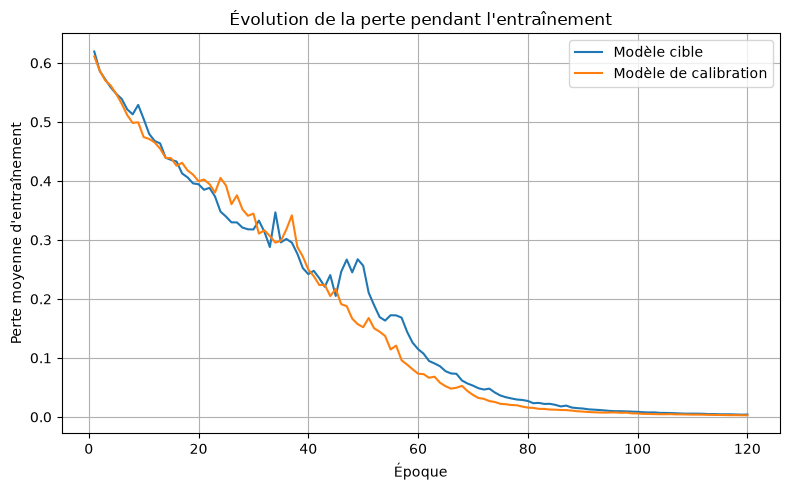

In [117]:
# 6. Plot the training-loss curves.

epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, target_losses, label="Modèle cible")
plt.plot(epochs, calibration_losses, label="Modèle de calibration")

plt.xlabel("Époque")
plt.ylabel("Perte moyenne d'entraînement")
plt.title("Évolution de la perte pendant l'entraînement")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Loss-based membership evidence from the black-box output

For a binary classifier, the target returns

$$
f_\theta(x)=[p_0(x),p_1(x)].
$$

If the candidate's true class is $y$, define the true-class confidence $p_y(x)$. The cross-entropy loss is

$$
\mathcal L(f_\theta(x),y)=-\log p_y(x).
$$

Use the continuous membership score

$$
s_{\mathrm{loss}}(x,y)=\log p_y(x)=-\mathcal L(f_\theta(x),y).
$$

Larger $s_{\mathrm{loss}}$ means larger true-class confidence and smaller loss.

The model does **not** return a membership probability. The attacker derives the membership score from the returned class probabilities.


### Implementation 3 — Simulate black-box queries


In [118]:
# 1. Implement query_probabilities(model, loader) that returns only
#    class probabilities and labels. Do not access target parameters,
#    gradients, or activations from the attack code.
#
# 2. Extract true-class confidence p_y for every record.
#
# 3. Compute:
#       loss = -log(p_y)
#       s_loss = log(p_y)
#
# 4. Collect scores for:
#       - target members
#       - target non-members
#       - auxiliary members
#       - auxiliary non-members
#
# 5. Plot the target member/non-member distributions of p_y.
#
# 6. Plot the target member/non-member distributions of log(p_y).
#
# 7. Report mean confidence and mean loss for target members/non-members.


### Question 3 — Interpret the black-box signal

1. Are target member scores shifted relative to target non-member scores?
2. Is the separation complete?
3. Which quantity was returned by the target model?
4. Which quantities were computed by the attacker?
5. Why is $s_{\mathrm{loss}}$ a membership **score** rather than a membership probability?


**Write your response here:**

<br><br><br><br>


## 4. Evaluate one threshold: TP, FN, FP, TN

Use the auxiliary experiment to choose a threshold $\tau$ **without using target membership labels**.

Predict member when

$$
\hat m=
\begin{cases}
1,&s_{\mathrm{loss}}\ge\tau,\\
0,&s_{\mathrm{loss}}<\tau.
\end{cases}
$$

For this laboratory, choose the auxiliary threshold that gives the largest fraction of correct member/non-member decisions on the balanced auxiliary evaluation set.

After fixing $\tau$, apply it once to the target candidates.

A true positive (TP) is an actual member predicted as a member.  
A false negative (FN) is an actual member predicted as a non-member.  
A false positive (FP) is an actual non-member predicted as a member.  
A true negative (TN) is an actual non-member predicted as a non-member.

Then compute

$$
\mathrm{TPR}=\frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}},
\qquad
\mathrm{FPR}=\frac{\mathrm{FP}}{\mathrm{FP}+\mathrm{TN}}.
$$


### Implementation 4 — Calibrate one threshold and build the confusion matrix


In [119]:
# 1. Combine auxiliary member and non-member scores with membership labels.
#
# 2. Sweep auxiliary thresholds and select tau using only auxiliary
#    membership labels. For this lab, choose the threshold with the
#    highest auxiliary membership-decision accuracy.
#
# 3. Fix tau.
#
# 4. Apply tau to the target member/non-member scores.
#
# 5. Compute TP, FN, FP, TN.
#
# 6. Display a 2 x 2 confusion matrix.
#
# 7. Compute target TPR and FPR at this one threshold.


### Question 4 — Interpret one operating point

1. What does the measured TPR mean in this experiment?
2. What does the measured FPR mean?
3. Why was $\tau$ calibrated on auxiliary data rather than chosen from target membership labels?
4. Does one pair $(\mathrm{FPR},\mathrm{TPR})$ completely describe the quality of the continuous attack score?


**Write your response here:**

<br><br><br><br>


## 5. Move the threshold: ROC curve and AUC

The result depends on where $\tau$ is placed.

A **larger** threshold is stricter: fewer records are predicted as members. It usually reduces both TPR and FPR.

A **smaller** threshold is less strict: more records are predicted as members. It usually increases both TPR and FPR.

As $\tau$ varies, each threshold gives one operating point

$$
(\mathrm{FPR},\mathrm{TPR}).
$$

Sweeping the threshold traces the **receiver operating characteristic (ROC) curve**.

The **area under the ROC curve (AUC)** summarizes the ranking quality of the continuous attack score:

$$
\mathrm{AUC}=0.5
$$

corresponds to random ranking, while

$$
\mathrm{AUC}=1
$$

corresponds to perfect member/non-member separation.

Under the convention that larger scores mean stronger membership evidence,

$$
\mathrm{AUC}
=
\Pr(S_{\mathrm{member}}>S_{\mathrm{nonmember}})
$$

up to tie handling.


### Implementation 5 — Observe threshold movement and construct ROC/AUC


In [120]:
# 1. Choose three thresholds representing:
#       - less strict
#       - the auxiliary-calibrated tau
#       - strict
#
# 2. For each threshold, compute target FPR and TPR.
#
# 3. Display the three operating points in a table.
#
# 4. Sweep all thresholds and compute the target ROC curve.
#
# 5. Plot TPR against FPR.
#
# 6. Compute the AUC.


### Question 5 — Interpret ROC and AUC

1. What happened to TPR and FPR when the threshold became less strict?
2. Why does the attack not have one unique TPR/FPR pair?
3. Complete the sentence using your measured AUC:

   **"If I randomly choose one target member and one target non-member, the attack assigns the member a larger membership score approximately ____% of the time."**

4. Why does an AUC of $0.8$ **not** mean that a particular candidate has an 80% probability of being a member?


**Write your response here:**

<br><br><br><br>


## 6. Why one global threshold can fail

A single threshold treats the same absolute score in the same way for every record. But records differ in prediction difficulty.

Operationally in this laboratory:

- a **high-score non-member** is a record that the target model predicts with high true-class confidence even though the record was not used for training;
- a **low-score member** is a record that receives only moderate or low true-class confidence even though it was used for training.

These are the empirical counterparts of the lecture's "easy non-member" and "difficult member."

The evaluator may use the known target membership labels **after the attack has been run** to identify illustrative errors. Those labels were not used to choose the attack threshold.


### Implementation 6 — Find an easy non-member and a difficult member


In [121]:
# 1. Using the fixed global threshold tau, find:
#       - a target non-member with a high membership score;
#       - a target member with a low membership score.
#
# 2. Prefer a false positive and false negative if they exist.
#    If not, use the highest-scoring non-member and lowest-scoring member.
#
# 3. Display for both records:
#       - true membership
#       - clinical label y
#       - p_y
#       - s_loss = log(p_y)
#       - global-threshold decision
#
# 4. Plot both scores on one horizontal score axis with tau.
#
# 5. Display the two medical images.


### Question 6 — What does "easy" or "difficult" mean here?

1. "Easy" and "difficult" are with respect to what?
2. Why can a non-member receive a high score?
3. Why can a member receive only a moderate score?
4. If your run produced both a false positive and false negative, can moving a single global threshold necessarily correct both?
5. Why does this motivate comparing a candidate with **record-specific reference behaviour**?


**Write your response here:**

<br><br><br><br>


## 7. LiRA: construct record-specific IN and OUT behaviour

The Likelihood Ratio Attack (LiRA) treats membership as a hypothesis test for one candidate record $r$:

$$
H_{\mathrm{OUT}}: r\notin D_{\mathrm{train}},
\qquad
H_{\mathrm{IN}}: r\in D_{\mathrm{train}}.
$$

For the **same candidate record**, train reference models under both worlds:

- **IN reference models:** the reference model's training set contains $r$;
- **OUT reference models:** the reference model's training set does not contain $r$.

Evaluate the same candidate on every reference model.

For true-class confidence $p_y$, use the logit transformation

$$
q=\operatorname{logit}(p_y)
=
\log\frac{p_y}{1-p_y}.
$$

The logit maps $(0,1)$ to the real line. In LiRA, Gaussian distributions are fitted to the transformed scores:

$$
Q_{\mathrm{IN}}(r)
\approx
\mathcal N(\mu_{\mathrm{IN}},\sigma_{\mathrm{IN}}^2),
\qquad
Q_{\mathrm{OUT}}(r)
\approx
\mathcal N(\mu_{\mathrm{OUT}},\sigma_{\mathrm{OUT}}^2).
$$

These are distributions of **scores for the same record across reference models**. They are not distributions of medical images or different patients.

### Classroom construction

To keep the experiment CPU-feasible, use the two illustrative records selected in Section 6 and train 12 small reference models. Each candidate appears in six reference-model training sets and is absent from six.

Only six IN and six OUT scores are therefore available per candidate. The fitted curves are intentionally noisy and are used to demonstrate the LiRA construction rather than to claim a reliable privacy estimate.


### Question 7 — Before implementing LiRA

1. For one candidate record, what does one point in $Q_{\mathrm{IN}}(r)$ represent?
2. What does one point in $Q_{\mathrm{OUT}}(r)$ represent?
3. Are the IN and OUT curves distributions over different patients?
4. Why is this approach record-specific rather than global?


**Write your response here:**

<br><br><br>


### Implementation 7 — Train small IN/OUT reference ensembles


In [122]:
# 1. Define logit_confidence(p) = log(p / (1-p)) with numerical clipping.
#
# 2. Use the two illustrative records from Section 6 as candidate A and B.
#
# 3. Combine auxiliary_train and auxiliary_nonmember into an auxiliary pool.
#
# 4. Train 12 reference models. Use inclusion patterns so that each
#    candidate is present in exactly 6 training sets and absent from 6.
#
# 5. Keep every reference-model training set the same size by sampling
#    fewer auxiliary records when one or both candidates are included.
#
# 6. For each reference model:
#       - train a fresh SmallMedicalCNN for 40 epochs;
#       - query the SAME two candidate records;
#       - extract p_y;
#       - transform p_y to q = logit(p_y).
#
# 7. Store:
#       - whether each candidate was IN or OUT for that model;
#       - the corresponding q value.
#
# Suggested settings:
#       n_reference_models = 12
#       shadow_train_size = 120
#       shadow_epochs = 40


## 8. LiRA likelihood-ratio decision

Query the target model on the same candidate and obtain its transformed score $q_t$.

For each record, fit the two Gaussian reference distributions and evaluate their probability densities at $q_t$.

The LiRA statistic is

$$
\Lambda_{\mathrm{LiRA}}(r)
=
\frac{
\phi(q_t;\mu_{\mathrm{IN}},\sigma_{\mathrm{IN}}^2)
}{
\phi(q_t;\mu_{\mathrm{OUT}},\sigma_{\mathrm{OUT}}^2)
},
$$

where $\phi$ is the Gaussian probability density.

A large value means the observed target score is more plausible under the IN distribution than under the OUT distribution.

For the small demonstration below, use

$$
\Lambda_{\mathrm{LiRA}}\ge 1
$$

to say that the fitted IN density is at least as large as the fitted OUT density at the observed score. This is an illustrative operating threshold, not a universal optimal threshold.

In a full evaluation, the likelihood-ratio score can itself be swept over different thresholds, producing TPR/FPR operating points and an ROC curve exactly as for the earlier continuous attack score.


### Implementation 8 — Fit IN/OUT Gaussians and compute the likelihood ratio


In [123]:
# 1. Query the target model on the same two candidate records.
#
# 2. Transform target p_y values to q_t = logit(p_y).
#
# 3. For each candidate:
#       - split the reference q values into IN and OUT sets;
#       - fit a Gaussian mean and standard deviation to each set;
#       - evaluate both fitted densities at q_t;
#       - compute Lambda_LiRA = density_IN(q_t) / density_OUT(q_t).
#
# 4. For numerical stability, you may compute log Lambda first:
#       log Lambda = log density_IN - log density_OUT
#
# 5. For this demonstration, use Lambda >= 1 to indicate that the
#    observed score is more plausible under IN than OUT.
#
# 6. Display a table containing q_t, fitted means/standard deviations,
#    Lambda, and the favored hypothesis for both records.
#
# 7. For each candidate, create a separate plot showing:
#       - fitted OUT density
#       - fitted IN density
#       - vertical line at q_t


### Question 8 — Interpret LiRA

For each of the two records:

1. Is the observed $q_t$ more plausible under IN or OUT?
2. What is the sign of $\log\Lambda_{\mathrm{LiRA}}$?
3. Did the record-specific comparison agree with the true membership label?
4. Did it correct the global-threshold error, if there was one?

Then answer:

5. Why does LiRA not simply ask whether $q_t$ is "large"?
6. What does the vertical-axis density mean in the fitted-curve plot?
7. Why should you be cautious about conclusions from only six IN and six OUT scores?


**Write your response here:**

<br><br><br><br>


## 9. Online and offline LiRA

The implementation above is a small **online LiRA** construction because it explicitly estimates both record-specific distributions:

$$
Q_{\mathrm{IN}}(r)
\quad\text{and}\quad
Q_{\mathrm{OUT}}(r).
$$

This is expensive because the attacker needs reference models trained both with and without the candidate.

**Offline LiRA** avoids target-specific IN-model construction. It estimates how unusual the target score is under OUT reference behaviour, reducing the number of models that must be trained for a particular target record.

| Online LiRA | Offline LiRA |
|---|---|
| Estimates IN and OUT behaviour | Estimates OUT behaviour |
| Candidate-specific IN models required | No target-specific IN models |
| Full record-specific likelihood ratio | Tests how unusual the target score is under OUT |
| Higher computational cost | Lower computational cost |


### Question 9 — Online versus offline

1. Why is the LiRA implementation in this notebook "online"?
2. Which target-specific construction is removed in offline LiRA?
3. Why is offline LiRA computationally cheaper?
4. What information would still have to be available to evaluate the candidate under an OUT reference model?


**Write your response here:**

<br><br><br>


## 10. Privacy interpretation

This laboratory measures whether a model exposes information about **training-set membership**.

The attack already assumes knowledge of the candidate image and its ground-truth binary label. Therefore, successful membership inference does not by itself show that the attacker discovered whether the image is malignant.

The additional inferred fact is whether that labelled medical record was used to train the target model.

The privacy significance of membership depends on the provenance and meaning of the training cohort.


### Question 10 — State a defensible conclusion

Write a short conclusion that reports:

1. the loss-based attack AUC;
2. the TPR and FPR at the auxiliary-calibrated threshold;
3. what the easy-non-member / difficult-member analysis showed;
4. what the LiRA demonstration changed conceptually;
5. the limits of the experiment;
6. what privacy fact was inferred and what was **not** inferred.


**Write your response here:**

<br><br><br><br><br>


## Submission

Submit the completed notebook containing:

1. the verified four-way data partition;
2. target and calibration model training results;
3. target member/non-member confidence and loss-score distributions;
4. one fixed-threshold confusion matrix with TPR and FPR;
5. the threshold-sweep table, ROC curve, and AUC;
6. the high-score non-member / low-score member analysis;
7. the online LiRA reference-model construction for the two selected records;
8. fitted IN/OUT distributions and likelihood-ratio interpretation;
9. responses to Questions 1–10.


### References

[1] Carlini, N., Chien, S., Nasr, M. et al. Membership inference attacks from first principles. In: *2022 IEEE Symposium on Security and Privacy*, 1897–1914 (2022). https://doi.org/10.1109/SP46214.2022.9833649

[2] Yeom, S., Giacomelli, I., Fredrikson, M. et al. Privacy risk in machine learning: analyzing the connection to overfitting. In: *2018 IEEE 31st Computer Security Foundations Symposium*, 268–282 (2018). https://doi.org/10.1109/CSF.2018.00027

[3] Yang, J., Shi, R., Wei, D. et al. MedMNIST v2 — A large-scale lightweight benchmark for 2D and 3D biomedical image classification. *Scientific Data* 10, 41 (2023). https://doi.org/10.1038/s41597-022-01721-8

[4] Knolle, M.A., Menten, M.J., Jungmann, F. et al. Disparate privacy risks from medical AI. *Nature* 656, 192–198 (2026). https://doi.org/10.1038/s41586-026-10688-0
